In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pickle

with open("/content/drive/MyDrive/Colab Notebooks/beth_prepared.pkl", "rb") as f:
    dati_preparati = pickle.load(f)

X_train = dati_preparati["X_train"]
X_validation = dati_preparati["X_validation"]
X_test = dati_preparati["X_test"]

X_train_rel = dati_preparati["X_train_rel"]
X_validation_rel = dati_preparati["X_validation_rel"]
X_test_rel = dati_preparati["X_test_rel"]

y_train = dati_preparati["y_train"]
y_validation = dati_preparati["y_validation"]
y_test = dati_preparati["y_test"]

event_features = dati_preparati["event_features"]

print("Dati caricati.")

Dati caricati.


In [ ]:
print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_validation:", y_validation.shape)
print("y_test:", y_test.shape)

X_train: (128, 32)
X_validation: (22, 32)
X_test: (13, 32)
y_train: (128, 5)
y_validation: (22, 5)
y_test: (13, 5)


X_train       → 128 finestre × 32 feature

X_validation  → 22 finestre × 32 feature

X_test        → 13 finestre × 32 feature

y_train       → 128 finestre × 5 informazioni

y_validation  → 22 finestre × 5 informazioni

y_test        → 13 finestre × 5 informazioni

Perché y è 5 invece di 2?

In realtà le label che ci interessano sono 2:

sus_window
evil_window

Le altre tre colonne che abbiamo messo dentro y:

n_events
sus
evil


In [ ]:
y_train_sus = y_train["sus_window"]
y_validation_sus = y_validation["sus_window"]
y_test_sus = y_test["sus_window"]

y_train_evil = y_train["evil_window"]
y_validation_evil = y_validation["evil_window"]
y_test_evil = y_test["evil_window"]

print("SUS:")
print("TRAIN:", y_train_sus.value_counts().to_dict())
print("VALIDATION:", y_validation_sus.value_counts().to_dict())
print("TEST:", y_test_sus.value_counts().to_dict())

print("\nEVIL:")
print("TRAIN:", y_train_evil.value_counts().to_dict())
print("VALIDATION:", y_validation_evil.value_counts().to_dict())
print("TEST:", y_test_evil.value_counts().to_dict())

SUS:
TRAIN: {0: 120, 1: 8}
VALIDATION: {0: 20, 1: 2}
TEST: {1: 7, 0: 6}

EVIL:
TRAIN: {0: 128}
VALIDATION: {0: 22}
TEST: {0: 8, 1: 5}


Perché lo facciamo?

Perché il modello è non supervisionato: non gli daremo sus_window o evil_window durante l'addestramento.

Le useremo dopo, per verificare se le finestre che il modello considera anomale corrispondono effettivamente alle finestre SUS/EVIL.

Quindi il nostro scenario è:

TRAIN: 128 finestre, di cui 8 SUS e 0 EVIL

VALIDATION: 22 finestre, di cui 2 SUS e 0 EVIL

TEST: 13 finestre, di cui 7 SUS e 5 EVIL

Questo ha senso per un problema di anomaly detection non supervisionata: il training è sostanzialmente costituito da comportamento normale, e poi testiamo se il modello assegna score anomali alle finestre contenenti attività sospetta/malevola.

Le label servono per la valutazione, non per il training.

Dopo la standardizzazione, le feature vengono trasformate in modo che il modello possa confrontarle su una scala comune.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

Xs_train = scaler.fit_transform(X_train_rel)
Xs_validation = scaler.transform(X_validation_rel)
Xs_test = scaler.transform(X_test_rel)

print("Xs_train:", Xs_train.shape)
print("Xs_validation:", Xs_validation.shape)
print("Xs_test:", Xs_test.shape)

Xs_train: (128, 32)
Xs_validation: (22, 32)
Xs_test: (13, 32)


# **`ISOLATION FOREST`**

Ogni riga rappresenta una finestra e ogni colonna un tipo di evento.

Isolation Forest cerca di capire quali finestre sono più isolate rispetto alle altre.

se una finestra ha una composizione di eventi molto diversa dalle altre finestre del training, dovrebbe essere più facile da "isolare" e quindi ricevere uno score più anomalo.
Non gli diciamo quali finestre sono SUS o EVIL.

In [ ]:
from sklearn.ensemble import IsolationForest

if_model = IsolationForest(
    n_estimators=200,
    random_state=42,
    contamination="auto"
)

if_model.fit(Xs_train)

print("Isolation Forest addestrato.")

Isolation Forest addestrato.


n_estimators=200
significa che Isolation Forest costruisce 200 alberi. Più alberi generalmente rende la stima più stabile.
random_state=42
serve per ottenere gli stessi risultati quando rieseguiamo il codice.
contamination="auto"
dice al modello di non imporre noi una percentuale di anomalie.


In [ ]:
score_train = -if_model.decision_function(Xs_train)
score_validation = -if_model.decision_function(Xs_validation)
score_test = -if_model.decision_function(Xs_test)

print("Score TRAIN:", score_train.shape)
print("Score VALIDATION:", score_validation.shape)
print("Score TEST:", score_test.shape)

Score TRAIN: (128,)
Score VALIDATION: (22,)
Score TEST: (13,)


IsolationForest.decision_function() assegna valori in cui, sostanzialmente, valori più bassi indicano maggiore anomalia.

Noi vogliamo invece avere una convenzione più intuitiva:
score basso  → normale
score alto   → anomalo
Per questo cambiamo il segno. Così possiamo dire:

più alto è lo score, più la finestra viene considerata anomala.

In [ ]:
import pandas as pd

risultati_if = pd.DataFrame({
    "window": range(len(score_test)),
    "anomaly_score": score_test,
    "sus": y_test_sus.values,
    "evil": y_test_evil.values
})

print(risultati_if)

    window  anomaly_score  sus  evil
0        0       0.118571    1     1
1        1       0.029523    0     0
2        2      -0.141489    0     0
3        3      -0.078555    1     0
4        4      -0.137830    1     0
5        5       0.086359    0     0
6        6      -0.128510    0     0
7        7      -0.001065    0     0
8        8      -0.086880    0     0
9        9       0.067707    1     1
10      10       0.012174    1     1
11      11      -0.000040    1     1
12      12       0.005907    1     1


In [ ]:
risultati_if.sort_values(
    "anomaly_score",
    ascending=False
)

,window,anomaly_score,sus,evil
0,0,0.118571,1,1
5,5,0.086359,0,0
9,9,0.067707,1,1
1,1,0.029523,0,0
10,10,0.012174,1,1
12,12,0.005907,1,1
11,11,-0.000040,1,1
7,7,-0.001065,0,0
3,3,-0.078555,1,0
8,8,-0.086880,0,0


lo score non è una probabilità. È semplicemente un punteggio prodotto dal modello, che possiamo usare per ordinare le finestre e per stabilire una soglia. Nell'ultima tabella ci sono gli anomaly score ordinati dal più anomalo al meno anomalo.

La ROC ci permette di provare diverse soglie e vedere cosa succede.
soglia molto bassa
       ↓
quasi tutto viene classificato come anomalo

soglia più alta
       ↓
solo le finestre con score molto alto vengono classificate come anomale

Per ogni soglia possiamo contare:

quante anomalie vere abbiamo trovato → True Positive
quante normali abbiamo erroneamente classificato come anomalie → False Positive

e da questo costruire la curva ROC.
L'AUC riassume quanto bene gli score riescono a separare le due classi.

Isolation Forest assegna a ogni finestra uno score. Più alto è lo score, più la finestra viene considerata anomala secondo il modello.
Poi noi dobbiamo verificare quanto questa graduatoria corrisponde davvero alle label SUS/EVIL.

In [ ]:
print("Finestre SUS ordinate per anomaly score:")
print(
    risultati_if[risultati_if["sus"] == 1][
        ["window", "anomaly_score", "sus", "evil"]
    ]
)

print("\nFinestre EVIL ordinate per anomaly score:")
print(
    risultati_if[risultati_if["evil"] == 1][
        ["window", "anomaly_score", "sus", "evil"]
    ]
)

Finestre SUS ordinate per anomaly score:
    window  anomaly_score  sus  evil
0        0       0.118571    1     1
3        3      -0.078555    1     0
4        4      -0.137830    1     0
9        9       0.067707    1     1
10      10       0.012174    1     1
11      11      -0.000040    1     1
12      12       0.005907    1     1

Finestre EVIL ordinate per anomaly score:
    window  anomaly_score  sus  evil
0        0       0.118571    1     1
9        9       0.067707    1     1
10      10       0.012174    1     1
11      11      -0.000040    1     1
12      12       0.005907    1     1


Tutte e 7 sono finestre SUS, ma l'Isolation Forest assegna loro score molto diversi.

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_true_evil = y_test_evil.values

fpr_evil, tpr_evil, thresholds_evil = roc_curve(
    y_true_evil,
    score_test
)

auc_evil = roc_auc_score(
    y_true_evil,
    score_test
)

print("AUC EVIL:", auc_evil)

AUC EVIL: 0.825


Gli anomaly score dell'Isolation Forest riescono a distinguere le finestre EVIL dalle finestre non-EVIL?
EVIL positive = 5
EVIL negative = 8
AUC = 0.825

è interessante, ma è calcolato su soltanto 13 finestre.
E soprattutto: abbiamo solo 5 EVIL nel test

Sul test set, l'Isolation Forest ha ottenuto un'AUC di 0.825 per il rilevamento delle finestre EVIL. Il risultato indica una buona capacità di separazione degli score, ma deve essere interpretato con cautela a causa del numero ridotto di finestre disponibili nel test set.

Adesso facciamo la stessa cosa per SUS

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

y_true_sus = y_test_sus.values

fpr_sus, tpr_sus, thresholds_sus = roc_curve(
    y_true_sus,
    score_test
)

auc_sus = roc_auc_score(
    y_true_sus,
    score_test
)

print("AUC SUS:", auc_sus)

AUC SUS: 0.6428571428571429


se cambio la soglia, come cambia il comportamento del modello?

TPR — True Positive Rate

Risponde alla domanda:

Tra tutte le anomalie vere, quante ne ho trovate?

Quindi è anche chiamato recall/sensitivity.

FPR — False Positive Rate

Risponde alla domanda:

Tra tutte le finestre normali, quante ne ho erroneamente dichiarate anomale?

Quindi:

TPR alto → bene,
trovo molte anomalie vere

FPR basso → bene, faccio pochi falsi allarmi

La ROC cerca proprio di studiare questo compromesso.


In [ ]:
roc_sus = pd.DataFrame({
    "threshold": thresholds_sus,
    "FPR": fpr_sus,
    "TPR": tpr_sus
})

print(roc_sus)

    threshold       FPR       TPR
0         inf  0.000000  0.000000
1    0.118571  0.000000  0.142857
2    0.086359  0.166667  0.142857
3    0.067707  0.166667  0.285714
4    0.029523  0.333333  0.285714
5   -0.000040  0.333333  0.714286
6   -0.001065  0.500000  0.714286
7   -0.078555  0.500000  0.857143
8   -0.128510  0.833333  0.857143
9   -0.137830  0.833333  1.000000
10  -0.141489  1.000000  1.000000


In [ ]:
roc_evil = pd.DataFrame({
    "threshold": thresholds_evil,
    "FPR": fpr_evil,
    "TPR": tpr_evil
})

print(roc_evil)

   threshold    FPR  TPR
0        inf  0.000  0.0
1   0.118571  0.000  0.2
2   0.086359  0.125  0.2
3   0.067707  0.125  0.4
4   0.029523  0.250  0.4
5  -0.000040  0.250  1.0
6  -0.141489  1.000  1.0


La curva ROC mette:
asse X → FPR
asse Y → TPR

La ROC è la curva ottenuta facendo variare la soglia.

L'AUC è l'area sotto quella curva.

AUC EVIL = 0.825
Questo significa, in termini generali, che gli anomaly score hanno una buona capacità di ordinare/separare le finestre EVIL da quelle non-EVIL.

Per SUS invece:

AUC SUS = 0.642857

quindi la separazione ottenuta dagli score è più debole


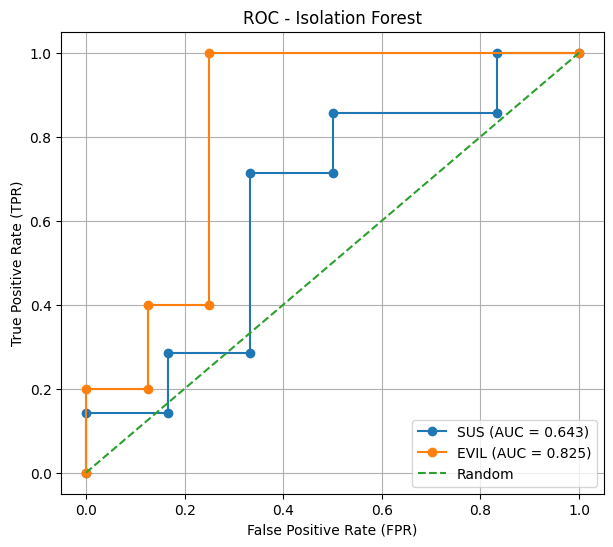

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

# Curva ROC SUS
plt.plot(
    fpr_sus,
    tpr_sus,
    marker="o",
    label=f"SUS (AUC = {auc_sus:.3f})"
)

# Curva ROC EVIL
plt.plot(
    fpr_evil,
    tpr_evil,
    marker="o",
    label=f"EVIL (AUC = {auc_evil:.3f})"
)

# Classificatore casuale
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC - Isolation Forest")
plt.legend()
plt.grid(True)
plt.show()

asse X = FPR → falsi positivi

asse Y = TPR → veri positivi

linea SUS → comportamento dell'Isolation Forest rispetto a SUS

linea EVIL → comportamento rispetto a EVIL

linea diagonale → riferimento di un classificatore casuale.

Ogni pallino della curva corrisponde a una delle soglie che abbiamo appena visto nelle tabelle.

Quella tratteggiata verde è il riferimento Random.

Rappresenta, in sostanza, un sistema che non riesce a distinguere le finestre positive da quelle negative.

La sua AUC è:

AUC=0.5

Quindi:

AUC ≈ 0.5 → separazione simile al caso casuale
AUC > 0.5 → il modello ha capacità di separazione
AUC più vicino a 1 → separazione migliore

La curva arancione è:

EVIL — AUC = 0.825

È abbastanza distante dalla diagonale verde e tende verso l'angolo in alto a sinistra.

Questo è coerente con quello che avevamo visto nella tabella degli score: diverse finestre EVIL ricevono score relativamente elevati.

In particolare, la curva arriva a:

FPR ≈ 0.25
TPR = 1.0

Questo significa che a una certa soglia possiamo trovare tutte le 5 finestre EVIL, accettando però alcuni falsi positivi.

Attenzione: non significa che questa sia necessariamente la soglia che dobbiamo scegliere.


La curva blu: SUS

La curva blu è:

SUS — AUC = 0.643

È comunque sopra la diagonale in buona parte del grafico, ma è più vicina alla linea casuale rispetto a EVIL.

Quindi, nel nostro test:

Isolation Forest separa meglio EVIL da non-EVIL che SUS da non-SUS.

Le curve sono a gradini. Abbiamo soltanto 13 finestre di test, quindi abbiamo pochissimi valori possibili. Quando cambiamo soglia, cambiamo classificazione di una o più di queste 13 finestre.

Per questo la curva non è liscia: fa dei salti.

Questa è anche una delle ragioni per cui dobbiamo essere prudenti nell'interpretare AUC = 0.825.

L'AUC di 0.825 indica che, nel test set considerato, gli anomaly score dell'Isolation Forest mostrano una buona capacità di discriminare le finestre EVIL da quelle non-EVIL.

E per SUS:

L'AUC di 0.643 indica una capacità discriminativa più limitata rispetto a EVIL.


Il prossimo passo: scegliere la soglia

non dobbiamo scegliere la soglia guardando il test set, altrimenti rischiamo di usare il test per prendere decisioni sul modello.

Abbiamo infatti un validation set di 22 finestre, che possiamo utilizzare proprio per questo.

Prima costruiamo le soglie sul TRAIN

possiamo guardare come sono distribuiti gli score delle finestre TRAIN, che sono il nostro riferimento per il comportamento "normale".

In [ ]:
import numpy as np
import pandas as pd

# Alcuni percentili degli anomaly score del TRAIN
percentili = [90, 95, 97, 99]

soglie = {
    f"{p}%": np.percentile(score_train, p)
    for p in percentili
}

print("Soglie candidate:")
for p, soglia in soglie.items():
    print(f"{p}: {soglia:.6f}")

Soglie candidate:
90%: 0.010613
95%: 0.041385
97%: 0.049094
99%: 0.084023


Poi vediamo cosa succede sul VALIDATION

In [ ]:
for nome, soglia in soglie.items():

    pred_validation = (score_validation >= soglia).astype(int)

    print(f"\nSoglia {nome} = {soglia:.6f}")
    print("Finestre considerate anomale:",
          np.where(pred_validation == 1)[0])


Soglia 90% = 0.010613
Finestre considerate anomale: [ 0  6 10]

Soglia 95% = 0.041385
Finestre considerate anomale: [0]

Soglia 97% = 0.049094
Finestre considerate anomale: []

Soglia 99% = 0.084023
Finestre considerate anomale: []


Ricordiamo che nel validation avevamo:

22 finestre totali

2 finestre SUS: 0 e 21

20 finestre non-SUS

nessuna finestra EVIL

*Soglia 90%*

Il modello segnala:

0, 6, 10

La finestra 0 è effettivamente SUS

Ma 6 e 10 non sono SUS → falsi positivi.

Inoltre non segnala la finestra 21, che invece è SUS → falso negativo.

Quindi la soglia 90% non è particolarmente buona per SUS.

*Soglia 95%*

Segnala soltanto:

0

La 0 è SUS

Però non trova la 21.

Quindi abbiamo meno falsi positivi rispetto alla soglia 90%, ma perdiamo comunque una delle due anomalie SUS.

*Soglie 97% e 99%*

Non segnalano nessuna finestra.

Quindi perdono entrambe le finestre SUS.


AUC → qualità generale dello score

Precision/Recall/F1 → comportamento dopo aver scelto una soglia specifica

Dobbiamo definire una metrica con cui confrontare le soglie.

Possiamo calcolare per ogni soglia:

Precision → delle finestre che ho dichiarato anomale, quante lo erano davvero?

Recall/TPR → delle anomalie vere, quante ne ho trovate?

F1 → compromesso tra precision e recall.

Questo ci permette di dire numericamente quale soglia funziona meglio sul validation.

Per EVIL, il validation set non ci aiuta a scegliere la soglia, perché abbiamo:

VALIDATION EVIL:

0 EVIL

22 non-EVIL

Non abbiamo nessuna EVIL vera nel validation.

Quindi non possiamo valutare il recall EVIL sul validation.

In [ ]:
print("Tipo y_validation:", type(y_validation))
print("Colonne:", y_validation.columns)

print("\nValori di y_validation['sus']:")
print(y_validation["sus"].value_counts())

print("\nValori unici:")
print(y_validation["sus"].unique())

Tipo y_validation: <class 'pandas.core.frame.DataFrame'>
Colonne: Index(['n_events', 'sus', 'evil', 'sus_window', 'evil_window'], dtype='object')

Valori di y_validation['sus']:
sus
0      20
777     1
9       1
Name: count, dtype: int64

Valori unici:
[777   0   9]


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

# Label binaria SUS per ogni finestra
y_val_sus = np.asarray(y_validation["sus_window"]).ravel()

print("Label SUS validation:")
print(y_val_sus)

print("\nValori unici:")
print(np.unique(y_val_sus))

print("\nRisultati sul VALIDATION per SUS\n")

for nome, soglia in soglie.items():

    # 1 = finestra considerata anomala
    # 0 = finestra considerata normale
    pred = (score_validation >= soglia).astype(int)

    precision = precision_score(
        y_val_sus,
        pred,
        zero_division=0
    )

    recall = recall_score(
        y_val_sus,
        pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val_sus,
        pred,
        zero_division=0
    )

    print(f"Soglia {nome} = {soglia:.6f}")
    print(f"  Precision: {precision:.3f}")
    print(f"  Recall:    {recall:.3f}")
    print(f"  F1:        {f1:.3f}")
    print(f"  Finestre anomale: {np.where(pred == 1)[0]}")
    print()

Label SUS validation:
[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]

Valori unici:
[0 1]

Risultati sul VALIDATION per SUS

Soglia 90% = 0.010613
  Precision: 0.333
  Recall:    0.500
  F1:        0.400
  Finestre anomale: [ 0  6 10]

Soglia 95% = 0.041385
  Precision: 1.000
  Recall:    0.500
  F1:        0.667
  Finestre anomale: [0]

Soglia 97% = 0.049094
  Precision: 0.000
  Recall:    0.000
  F1:        0.000
  Finestre anomale: []

Soglia 99% = 0.084023
  Precision: 0.000
  Recall:    0.000
  F1:        0.000
  Finestre anomale: []



Per SUS, sulla base delle quattro soglie candidate che abbiamo provato sul validation:

la soglia del 95% (0.041385) è la candidata migliore, perché ha il valore F1 più alto: 0,667.

Questo è importante perché la soglia è stata scelta usando il validation, non il test.

Adesso applichiamo la soglia SUS scelta sul validation al TEST.

In [ ]:
# Soglia SUS scelta sul validation
soglia_sus = 0.041385

# Predizione SUS sul TEST
pred_test_sus = (score_test >= soglia_sus).astype(int)

print("Finestre TEST dichiarate SUS:")
print(np.where(pred_test_sus == 1)[0])

print("\nPredizioni:")
print(pred_test_sus)

print("\nLabel SUS reali:")
print(y_test["sus_window"].values)

Finestre TEST dichiarate SUS:
[0 5 9]

Predizioni:
[1 0 0 0 0 1 0 0 0 1 0 0 0]

Label SUS reali:
[1 0 0 1 1 0 0 0 0 1 1 1 1]


Ora calcoliamo le metriche finali SUS sul TEST

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

y_true = y_test["sus_window"].values
y_pred = pred_test_sus

cm = confusion_matrix(y_true, y_pred)

precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

print("Matrice di confusione:")
print(cm)

print("\nMetriche TEST - SUS")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")

Matrice di confusione:
[[5 1]
 [5 2]]

Metriche TEST - SUS
Precision: 0.667
Recall:    0.286
F1-score:  0.400


Quindi:

TN = 5 → 5 finestre normali riconosciute correttamente
FP = 1 → 1 finestra normale classificata erroneamente come SUS
FN = 5 → 5 finestre SUS non riconosciute
TP = 2 → 2 finestre SUS riconosciute correttamente


Precision 0,667

Quando il modello dice:

"Questa finestra è SUS"

ha ragione circa 2 volte su 3.

Quindi non genera moltissimi falsi allarmi.

Recall 0,286

Questo invece è il problema principale.

Delle 7 finestre SUS reali nel test, il modello ne trova soltanto:

2 / 7 = 28,6%

le altre 5 vengono perse.

F1 = 0,400

È il compromesso tra precision e recall. Il valore non è particolarmente alto, soprattutto perché il recall è basso.


Nel validation non avevamo finestre EVIL, quindi non possiamo scegliere una soglia EVIL nello stesso modo in cui abbiamo scelto quella SUS.

Quindi il validation non ci permette di ottimizzare una soglia EVIL: non avendo positivi, non possiamo calcolare un vero trade-off precision/recall per EVIL.

Possiamo applicare al TEST alcune soglie candidate, vedere quali finestre EVIL vengono intercettate e poi interpretare il risultato. Non chiameremo però questa "scelta ottimale" della soglia.

In [ ]:
import numpy as np

y_test_evil = np.asarray(y_test["evil_window"]).ravel()

print("Label EVIL reali nel TEST:")
print(y_test_evil)

print("\nFinestre realmente EVIL:")
print(np.where(y_test_evil == 1)[0])

Label EVIL reali nel TEST:
[1 0 0 0 0 0 0 0 0 1 1 1 1]

Finestre realmente EVIL:
[ 0  9 10 11 12]


Proviamo le soglie che abbiamo già

In [ ]:
soglie_evil = {
    "90%": 0.010613,
    "95%": 0.041385,
    "97%": 0.049094,
    "99%": 0.084023
}

for nome, soglia in soglie_evil.items():

    pred = (score_test >= soglia).astype(int)

    print(f"\nSoglia EVIL {nome} = {soglia:.6f}")
    print("Finestre dichiarate anomale:", np.where(pred == 1)[0])


Soglia EVIL 90% = 0.010613
Finestre dichiarate anomale: [ 0  1  5  9 10]

Soglia EVIL 95% = 0.041385
Finestre dichiarate anomale: [0 5 9]

Soglia EVIL 97% = 0.049094
Finestre dichiarate anomale: [0 5 9]

Soglia EVIL 99% = 0.084023
Finestre dichiarate anomale: [0 5]


Ora vediamo EVIL sul TEST con quelle quattro soglie.

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

y_true_evil = y_test["evil_window"].values

soglie_evil = {
    "90%": 0.010613,
    "95%": 0.041385,
    "97%": 0.049094,
    "99%": 0.084023
}

for nome, soglia in soglie_evil.items():

    # 1 = EVIL/anomalia, 0 = normale
    y_pred = (score_test >= soglia).astype(int)

    cm = confusion_matrix(y_true_evil, y_pred)

    precision = precision_score(
        y_true_evil, y_pred, zero_division=0
    )

    recall = recall_score(
        y_true_evil, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_true_evil, y_pred, zero_division=0
    )

    print("\n==============================")
    print(f"SOGLIA {nome} = {soglia:.6f}")
    print("==============================")

    print("Finestre predette EVIL:",
          np.where(y_pred == 1)[0])

    print("\nMatrice di confusione:")
    print(cm)

    print(f"Precision: {precision:.3f}")
    print(f"Recall:    {recall:.3f}")
    print(f"F1-score:  {f1:.3f}")


SOGLIA 90% = 0.010613
Finestre predette EVIL: [ 0  1  5  9 10]

Matrice di confusione:
[[6 2]
 [2 3]]
Precision: 0.600
Recall:    0.600
F1-score:  0.600

SOGLIA 95% = 0.041385
Finestre predette EVIL: [0 5 9]

Matrice di confusione:
[[7 1]
 [3 2]]
Precision: 0.667
Recall:    0.400
F1-score:  0.500

SOGLIA 97% = 0.049094
Finestre predette EVIL: [0 5 9]

Matrice di confusione:
[[7 1]
 [3 2]]
Precision: 0.667
Recall:    0.400
F1-score:  0.500

SOGLIA 99% = 0.084023
Finestre predette EVIL: [0 5]

Matrice di confusione:
[[7 1]
 [4 1]]
Precision: 0.500
Recall:    0.200
F1-score:  0.286


Per EVIL non è stato possibile selezionare una soglia ottimale tramite validation, poiché il validation set non contiene finestre EVIL. Pertanto, le soglie percentile sono state valutate sul test come analisi descrittiva, senza utilizzare il test per ottimizzare la soglia.

Quindi possiamo osservare che il 90% ha dato il risultato migliore sul test, ma non possiamo presentarlo come "la soglia scelta perché migliore".

Quindi, per EVIL, possiamo concludere che:

* l'AUC 0.825 indica che gli anomaly score hanno una buona capacità di distinguere le finestre EVIL dalle non-EVIL;
* tra le soglie che abbiamo analizzato, 90% produce sul test il miglior F1 (0.600);
* ma non possiamo dire che 90% sia stata scelta/ottimizzata sul validation, perché il validation non aveva esempi EVIL.

In [ ]:
# Riepilogo finale delle prestazioni

print("========================================")
print("        RISULTATI ISOLATION FOREST")
print("========================================")

print("\nSUS")
print("----------------------------------------")
print("AUC:", 0.6428571428571429)
print("Soglia scelta sul validation:", 0.041385)
print("Precision TEST:", 0.667)
print("Recall TEST:", 0.286)
print("F1 TEST:", 0.400)

print("\nEVIL")
print("----------------------------------------")
print("AUC:", 0.825)
print("Soglia selezionata sul validation: NON DISPONIBILE")
print("Motivo: validation non contiene finestre EVIL")
print(" ")
print("Risultati TEST per le soglie percentile:")

print("90% → Precision = 0.600 | Recall = 0.600 | F1 = 0.600")
print("95% → Precision = 0.667 | Recall = 0.400 | F1 = 0.500")
print("97% → Precision = 0.667 | Recall = 0.400 | F1 = 0.500")
print("99% → Precision = 0.500 | Recall = 0.200 | F1 = 0.286")

        RISULTATI ISOLATION FOREST

SUS
----------------------------------------
AUC: 0.6428571428571429
Soglia scelta sul validation: 0.041385
Precision TEST: 0.667
Recall TEST: 0.286
F1 TEST: 0.4

EVIL
----------------------------------------
AUC: 0.825
Soglia selezionata sul validation: NON DISPONIBILE
Motivo: validation non contiene finestre EVIL
 
Risultati TEST per le soglie percentile:
90% → Precision = 0.600 | Recall = 0.600 | F1 = 0.600
95% → Precision = 0.667 | Recall = 0.400 | F1 = 0.500
97% → Precision = 0.667 | Recall = 0.400 | F1 = 0.500
99% → Precision = 0.500 | Recall = 0.200 | F1 = 0.286


Cerchiamo di capire che cosa rende alcune finestre più anomale.

Prendiamo le finestre TEST e guardiamo, per ciascuna, quali eventName sono più presenti.

In [ ]:
# Eventi più frequenti nelle finestre TEST

for w in range(len(X_test)):

    print("\n" + "="*50)
    print(f"FINESTRA TEST {w}")
    print("="*50)

    # Prendiamo le 5 feature con frequenza maggiore
    top_features = X_test.iloc[w].sort_values(ascending=False).head(5)

    print(top_features)

    print("\nAnomaly score:", score_test[w])
    print("SUS:", y_test["sus_window"].iloc[w])
    print("EVIL:", y_test["evil_window"].iloc[w])


FINESTRA TEST 0
eventName
close                 1014
openat                 944
security_file_open     734
fstat                  483
cap_capable            277
Name: 0, dtype: int64

Anomaly score: 0.11857127516931742
SUS: 1
EVIL: 1

FINESTRA TEST 1
eventName
close                 4
fstat                 2
security_file_open    2
openat                2
socket                2
Name: 1, dtype: int64

Anomaly score: 0.02952325786376564
SUS: 0
EVIL: 0

FINESTRA TEST 2
eventName
openat                340
close                 338
security_file_open    334
stat                  105
fstat                  34
Name: 2, dtype: int64

Anomaly score: -0.14148893882791674
SUS: 0
EVIL: 0

FINESTRA TEST 3
eventName
close                 178
openat                122
security_file_open    115
fstat                 114
cap_capable            27
Name: 3, dtype: int64

Anomaly score: -0.07855523960813443
SUS: 1
EVIL: 0

FINESTRA TEST 4
eventName
openat                357
close                 356
secu

Le 32 feature che usiamo sono le frequenze relative degli eventi nella finestra.

Finestra 0 — SUS + EVIL: è uno degli score più alti del TEST.

Finestra 2 — normale: qui invece lo score è molto basso. Questo significa che, secondo il modello, questo profilo assomiglia maggiormente ai profili considerati normali nel TRAIN.

Finestra 3 — SUS ma non EVIL: È realmente SUS, però l'Isolation Forest le assegna uno score piuttosto basso.
**SUS non significa necessariamente "anomalo secondo l'Isolation Forest".**

Ed è proprio per questo che abbiamo ottenuto un'AUC SUS relativamente bassa: il modello non riesce sempre a separare bene SUS da non-SUS.

La finestra 5 è ancora più interessante: il modello la considera abbastanza anomala ma SUS=EVIL=0. Perché contiene pochissimi eventi ma costituiscono un profilo molto diverso dalle altre finestre.

Quindi l'Isolation Forest sta facendo esattamente quello per cui è stato costruito:

trova comportamenti/profili rari rispetto a quelli che ha visto nel TRAIN.

Ma attenzione: raro non significa necessariamente SUS o EVIL.




La finestra 11: ha SUS=EVIL=1 quindi è evil ma non ha uno score particolarmente alto. Lo stesso vale per la finestra 12. Queste due finestre sono un ottimo esempio del limite del metodo.

Il comportamento EVIL può essere molto caratteristico, ma non necessariamente "anomalo" rispetto al comportamento che l'Isolation Forest ha imparato.

Però, nel complesso, la distribuzione degli score delle EVIL è abbastanza separata da quella delle non-EVIL da produrre:

AUC = 0.825

Quindi AUC 0.825 è un buon segnale, anche se non significa che il modello riconosca perfettamente ogni singola finestra EVIL.

Una finestra può essere:

anomalia secondo IF + SUS/EVIL

oppure:

anomalia secondo IF + nessuna label

oppure:

SUS/EVIL + score basso

colleghiamo gli anomaly score alle predizioni e alle label reali:

In [ ]:
# Tabella completa del TEST

risultati_test = pd.DataFrame({
    "window": np.arange(len(score_test)),
    "anomaly_score": score_test,
    "SUS_reale": y_test["sus_window"].values,
    "EVIL_reale": y_test["evil_window"].values
})

# Usiamo la soglia SUS scelta sul validation
soglia_sus = 0.041385

# Per EVIL mostriamo, per ora, la soglia 90%
soglia_evil = 0.010613

risultati_test["SUS_predetto"] = (
    risultati_test["anomaly_score"] >= soglia_sus
).astype(int)

risultati_test["EVIL_predetto"] = (
    risultati_test["anomaly_score"] >= soglia_evil
).astype(int)

risultati_test

,window,anomaly_score,SUS_reale,EVIL_reale,SUS_predetto,EVIL_predetto
0,0,0.118571,1,1,1,1
1,1,0.029523,0,0,0,1
2,2,-0.141489,0,0,0,0
3,3,-0.078555,1,0,0,0
4,4,-0.137830,1,0,0,0
5,5,0.086359,0,0,1,1
6,6,-0.128510,0,0,0,0
7,7,-0.001065,0,0,0,0
8,8,-0.086880,0,0,0,0
9,9,0.067707,1,1,1,1


Quindi per SUS:

TP = 2 → finestre 0 e 9
TN = 5 → finestre 1, 2, 6, 7, 8
FP = 1 → finestra 5
FN = 5 → finestre 3, 4, 10, 11, 12

Precision = 0.667

Recall = 0.286

F1 = 0.400

l problema principale per SUS è evidente:

l'Isolation Forest trova solo 2 delle 7 finestre SUS.

Per questo il recall è basso (0.286).

Invece quando dichiara una finestra anomala, abbastanza spesso ci prende:

precision = 0.667

Questo ci dà già una spiegazione concreta del risultato SUS.


Per EVIL stiamo usando, solo per questa analisi sul TEST, la soglia 90%:

0.010613

Quindi abbiamo:

TP = 3 → finestre 0, 9, 10
TN = 6
FP = 2 → finestre 1, 5
FN = 2 → finestre 11, 12

Precision = 0.600

Recall = 0.600

F1 = 0.600

Per SUS, il modello trova solo 2 delle 7 finestre reali.

Per EVIL, con la soglia 90%, trova 3 delle 5 finestre reali.

Quindi, nei nostri dati, EVIL risulta più facilmente separabile tramite anomaly score rispetto a SUS, cosa coerente anche con l'AUC più alta: 0.825 > 0.643

Nel nostro TEST, gli anomaly score mostrano una capacità di discriminazione maggiore per EVIL rispetto a SUS (AUC 0.825 contro 0.643). Con la soglia percentile del 90%, EVIL raggiunge precision, recall e F1 pari a 0.600.

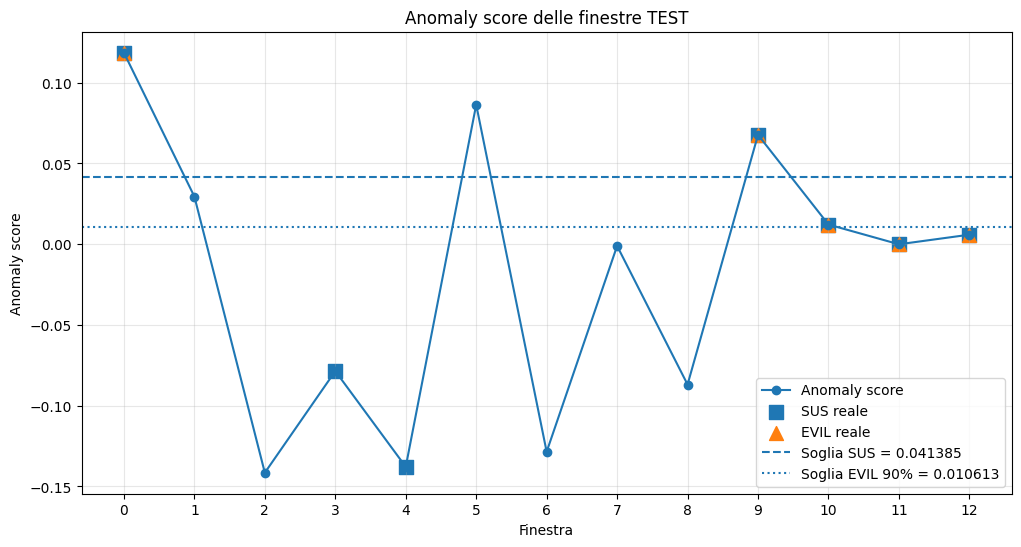

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Dati
windows = np.arange(len(score_test))
scores = score_test

sus_reale = y_test["sus_window"].values
evil_reale = y_test["evil_window"].values

plt.figure(figsize=(12, 6))

# Tutti gli anomaly score
plt.plot(
    windows,
    scores,
    marker="o",
    linestyle="-",
    label="Anomaly score"
)

# Evidenziamo le finestre SUS
plt.scatter(
    windows[sus_reale == 1],
    scores[sus_reale == 1],
    marker="s",
    s=100,
    label="SUS reale"
)

# Evidenziamo le finestre EVIL
plt.scatter(
    windows[evil_reale == 1],
    scores[evil_reale == 1],
    marker="^",
    s=100,
    label="EVIL reale"
)

# Soglia SUS scelta sul validation
plt.axhline(
    0.041385,
    linestyle="--",
    label="Soglia SUS = 0.041385"
)

# Soglia EVIL 90%, usata nell'analisi del TEST
plt.axhline(
    0.010613,
    linestyle=":",
    label="Soglia EVIL 90% = 0.010613"
)

plt.xlabel("Finestra")
plt.ylabel("Anomaly score")
plt.title("Anomaly score delle finestre TEST")
plt.xticks(windows)
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

Cosa vediamo per EVIL

Le finestre EVIL sono:

0, 9, 10, 11, 12

Nel grafico:

* finestra 0 → score 0.1186 → molto alto
* finestra 9 → 0.0677 → alto
* finestra 10 → 0.0122 → appena sopra la soglia EVIL
* finestra 11 → -0.00004 → sotto soglia
* finestra 12 → 0.0059 → sotto soglia

Quindi il modello non riconosce tutte le EVIL come anomalie.

Con la soglia EVIL 90% (0.010613), infatti, riconosce:

0, 9, 10

e perde:

11, 12

Da qui viene il Recall = 0.600.

Cosa vediamo per SUS

Le SUS sono:

0, 3, 4, 9, 10, 11, 12

E qui la situazione è molto più mista:

* 0  →  0.1186   ↑
* 3  → -0.0786   ↓
* 4  → -0.1378   ↓
* 9  →  0.0677   ↑
* 10 →  0.0122   ↑
* 11 → -0.00004
* 12 →  0.0059

Quindi alcune SUS hanno score molto alto, mentre altre hanno score molto basso.

Questo spiega bene perché l'AUC SUS = 0.643: c'è una certa capacità di separazione, ma non è particolarmente forte.

lo stesso anomaly score può essere interpretato diversamente a seconda della soglia che stiamo usando.

In [ ]:
print("Numero feature:", len(event_features))
print("Shape Xs_train:", Xs_train.shape)
print("Prime feature:", event_features[:10])

Numero feature: 32
Shape Xs_train: (128, 32)
Prime feature: ['accept', 'accept4', 'access', 'bind', 'cap_capable', 'clone', 'close', 'connect', 'dup', 'dup2']


In [ ]:
import pandas as pd
import numpy as np

rng = np.random.default_rng(42)
n_repeats = 30

# Baseline: anomaly score della VALIDATION non perturbata
baseline_scores_if = score_validation.copy()

feature_sensitivity_if = {}

for j, feature in enumerate(event_features):

    changes = []

    for _ in range(n_repeats):

        # Copia della validation standardizzata
        X_perm = Xs_validation.copy()

        # Permutiamo una sola feature
        X_perm[:, j] = rng.permutation(X_perm[:, j])

        # Stessa convenzione usata nel resto del notebook:
        # score più alto = maggiore anomalia
        perm_scores = -if_model.decision_function(X_perm)

        # Variazione media assoluta dell'anomaly score
        changes.append(
            np.mean(
                np.abs(
                    perm_scores - baseline_scores_if
                )
            )
        )

    feature_sensitivity_if[feature] = {
        "mean": np.mean(changes),
        "std": np.std(changes)
    }

sensitivity_sorted_if = sorted(
    feature_sensitivity_if.items(),
    key=lambda x: x[1]["mean"],
    reverse=True
)

print(
    "Top 10 feature per sensitivity "
    "- Isolation Forest (VALIDATION):"
)

for feature, values in sensitivity_sorted_if[:10]:
    print(
        f"{feature:30s} "
        f"{values['mean']:.6f} ± "
        f"{values['std']:.6f}"
    )

Top 10 feature per sensitivity - Isolation Forest (VALIDATION):
unlink                         0.012333 ± 0.001798
access                         0.011092 ± 0.001857
lstat                          0.010536 ± 0.001760
security_inode_unlink          0.008834 ± 0.001214
stat                           0.007013 ± 0.000821
getdents64                     0.006444 ± 0.000967
socket                         0.006164 ± 0.001255
sched_process_exit             0.006095 ± 0.001040
openat                         0.006026 ± 0.000735
security_file_open             0.006008 ± 0.000835


### Interpretazione della permutation sensitivity

La permutation sensitivity analysis è stata calcolata sul **validation set**, perturbando una feature alla volta e misurando la variazione media assoluta dell'anomaly score prodotto dall'Isolation Forest. La procedura è stata ripetuta 30 volte per ciascuna feature, in modo da stimare sia la sensitivity media sia la sua variabilità.

Le feature che mostrano la sensitivity più elevata sono:

1. `unlink` — 0.012333 ± 0.001798
2. `access` — 0.011092 ± 0.001857
3. `lstat` — 0.010536 ± 0.001760
4. `security_inode_unlink` — 0.008834 ± 0.001214
5. `stat` — 0.007013 ± 0.000821
6. `getdents64` — 0.006444 ± 0.000967
7. `socket` — 0.006164 ± 0.001255
8. `sched_process_exit` — 0.006095 ± 0.001040
9. `openat` — 0.006026 ± 0.000735
10. `security_file_open` — 0.006008 ± 0.000835

La feature `unlink` presenta la sensitivity media più elevata, seguita da `access` e `lstat`. Ciò indica che la permutazione di queste feature produce, in media, le variazioni più consistenti negli anomaly score assegnati dal modello alle osservazioni di validation.

Le deviazioni standard risultano relativamente contenute rispetto ai valori medi, suggerendo che l'effetto delle perturbazioni è sufficientemente stabile tra le 30 ripetizioni.

Questi risultati non devono tuttavia essere interpretati come una misura di importanza causale. Una sensitivity elevata indica esclusivamente che gli anomaly score prodotti dall'Isolation Forest sono particolarmente sensibili alla variazione di quella feature, nel contesto delle distribuzioni e delle dipendenze presenti nel validation set.


### Interpretazione della sensitivity

Per ciascuna feature viene misurata la variazione degli anomaly score dell'Isolation Forest quando i suoi valori vengono permutati nella **VALIDATION**, mantenendo inalterate tutte le altre feature.

Un valore più elevato di `mean` indica che gli anomaly score del modello sono maggiormente sensibili alla perturbazione di quella feature.

Il valore `std` misura invece la variabilità della sensitivity nelle 30 permutazioni effettuate.

L'utilizzo di un generatore pseudocasuale inizializzato con seed 42 rende l'esperimento riproducibile.

La sensitivity non indica che una feature sia di per sé anomala o associata causalmente a un'anomalia: misura esclusivamente quanto gli score prodotti dal modello cambiano quando viene perturbata quella feature.




In [ ]:
sensibilita_if_df = pd.DataFrame([
    {
        "feature": feature,
        "mean_sensitivity": values["mean"],
        "std_sensitivity": values["std"]
    }
    for feature, values in sensitivity_sorted_if
])

print("Shape sensitivity:", sensibilita_if_df.shape)
display(sensibilita_if_df.head(10))

Shape sensitivity: (32, 3)


,feature,mean_sensitivity,std_sensitivity
0,unlink,0.012333,0.001798
1,access,0.011092,0.001857
2,lstat,0.010536,0.001760
3,security_inode_unlink,0.008834,0.001214
4,stat,0.007013,0.000821
5,getdents64,0.006444,0.000967
6,socket,0.006164,0.001255
7,sched_process_exit,0.006095,0.001040
8,openat,0.006026,0.000735
9,security_file_open,0.006008,0.000835


In [ ]:
# Prime 10 feature secondo la sensitivity analysis sulla VALIDATION

top10_features_if = (
    sensibilita_if_df
    .head(10)["feature"]
    .tolist()
)

print("Top 10 feature - Isolation Forest (VALIDATION):")

for i, feature in enumerate(top10_features_if, start=1):
    print(f"{i:2d}. {feature}")

Top 10 feature - Isolation Forest (VALIDATION):
 1. unlink
 2. access
 3. lstat
 4. security_inode_unlink
 5. stat
 6. getdents64
 7. socket
 8. sched_process_exit
 9. openat
10. security_file_open


### Analisi delle feature più sensibili nelle finestre TEST

Dopo aver individuato le 10 feature alle quali l'Isolation Forest risulta maggiormente sensibile sulla **VALIDATION**, analizziamo i loro valori nelle 13 finestre del **TEST**.

L'obiettivo è verificare se le feature che influenzano maggiormente gli anomaly score mostrino pattern particolari nelle finestre con score elevato o nelle finestre etichettate come `SUS` o `EVIL`.

Per ciascuna finestra TEST consideriamo quindi:

* l'anomaly score prodotto dall'Isolation Forest;
* la label reale `SUS`;
* la label reale `EVIL`;
* i valori standardizzati delle 10 feature con sensitivity più elevata.


In [ ]:
# Prime 10 feature secondo la sensitivity analysis sulla VALIDATION

top10_features_if = (
    sensibilita_if_df
    .head(10)["feature"]
    .tolist()
)

print("Top 10 feature - Isolation Forest (VALIDATION):")
print(top10_features_if)

# Tabella TEST con:
# - indice della finestra
# - anomaly score
# - label reali SUS ed EVIL
# - valori standardizzati delle 10 feature più sensibili

tabella_feature_test_if = pd.DataFrame({
    "window": np.arange(len(Xs_test)),
    "anomaly_score": score_test,
    "SUS_reale": y_test["sus_window"].values,
    "EVIL_reale": y_test["evil_window"].values
})

for feature in top10_features_if:
    indice = event_features.index(feature)
    tabella_feature_test_if[feature] = Xs_test[:, indice]

tabella_feature_test_if

Top 10 feature - Isolation Forest (VALIDATION):
['unlink', 'access', 'lstat', 'security_inode_unlink', 'stat', 'getdents64', 'socket', 'sched_process_exit', 'openat', 'security_file_open']


,window,anomaly_score,SUS_reale,EVIL_reale,unlink,access,lstat,security_inode_unlink,stat,getdents64,socket,sched_process_exit,openat,security_file_open
0,0,0.118571,1,1,1.972730,-0.071923,3.131369,23.813596,-0.312660,1.145089,-0.422590,-0.069186,-0.282318,-0.400691
1,1,0.029523,0,0,-0.420510,-0.546936,-0.495569,-0.360962,-0.965603,-0.649089,3.203587,-0.422028,-1.744551,-0.820899
2,2,-0.141489,0,0,-0.420510,-0.488983,-0.495569,-0.360962,0.428457,-0.557883,-0.695987,-0.314409,1.023425,1.222804
3,3,-0.078555,1,0,-0.420510,-0.254149,-0.318144,-0.360962,-0.719656,0.886869,0.315196,-0.422028,-1.116903,-0.484337
4,4,-0.137830,1,0,-0.420510,-0.492365,-0.495569,-0.360962,0.347118,-0.563205,-0.630602,-0.118009,0.962500,1.134653
5,5,0.086359,0,0,-0.420510,-0.546936,-0.495569,-0.360962,-0.965603,-0.649089,-0.719621,41.262306,-4.385264,-2.840273
6,6,-0.128510,0,0,-0.420510,-0.492847,-0.495569,-0.360962,0.471828,-0.138337,-0.499039,-0.020251,0.751930,1.020055
7,7,-0.001065,0,0,-0.420510,-0.546936,-0.495569,-0.360962,-0.965603,-0.649089,3.203587,17.442687,-1.744551,-0.820899
8,8,-0.086880,0,0,0.317219,-0.495687,0.156611,3.986002,0.220232,0.318775,-0.698721,-0.041349,0.791659,1.000225
9,9,0.067707,1,1,-0.343081,0.146941,-0.128871,-0.132841,1.777464,0.256696,-0.572651,0.147326,-0.962747,-0.762751


### Interpretazione dei valori delle feature nel TEST

I valori riportati nella tabella sono **standardizzati rispetto alla distribuzione del TRAIN**.

Poiché lo `StandardScaler` è stato stimato sul training set, un valore vicino a `0` indica che la feature assume un valore vicino alla media osservata nel TRAIN, mentre valori positivi o negativi di grande ampiezza indicano uno scostamento consistente rispetto alla distribuzione di training.

La tabella mostra alcuni scostamenti particolarmente marcati. Ad esempio:

* nella window 0, `security_inode_unlink` assume un valore standardizzato pari a circa `23.81`;
* nella window 5, `sched_process_exit` raggiunge circa `41.26`;
* nella window 7, `sched_process_exit` raggiunge circa `17.44`;
* nelle window 11 e 12, `openat` e `security_file_open` presentano valori fortemente negativi.

Questi valori indicano che alcune finestre TEST presentano caratteristiche molto lontane da quelle osservate nel TRAIN.

Tuttavia, uno scostamento molto elevato di una singola feature non implica necessariamente un anomaly score altrettanto elevato, perché l'Isolation Forest valuta ciascuna osservazione sulla base della combinazione complessiva delle feature.


### Relazione tra sensitivity e anomaly score

La feature con sensitivity più elevata sulla VALIDATION è `unlink`, seguita da `access`, `lstat` e `security_inode_unlink`.

Nel TEST, tuttavia, non emerge una relazione semplice del tipo:

`valore elevato della feature → anomaly score elevato`.

Ad esempio, la window 0 presenta l'anomaly score più elevato (`0.118571`) e mostra valori particolarmente elevati per `unlink`, `lstat` e soprattutto `security_inode_unlink`.

La window 5 presenta invece il secondo anomaly score più elevato (`0.086359`), ma il comportamento più evidente tra le feature considerate riguarda `sched_process_exit`, che assume un valore standardizzato estremamente elevato (`41.26`).

Anche la window 9 presenta un anomaly score relativamente elevato (`0.067707`), ma mostra un profilo differente dalle precedenti.

Questo conferma che non esiste un unico profilo associato alle finestre considerate anomale dall'Isolation Forest: osservazioni diverse possono ottenere anomaly score elevati a causa di combinazioni differenti di feature.

La permutation sensitivity deve quindi essere interpretata come una misura della sensibilità globale del modello rispetto alle feature, e non come una regola deterministica che associa direttamente il valore di una singola feature allo score di anomalia.


In [ ]:
# Analisi dei valori originali delle Top 10 feature per sensitivity

top10_features_if = (
    sensibilita_if_df
    .head(10)["feature"]
    .tolist()
)

# Recuperiamo dal TEST i valori originali delle feature,
# prima della standardizzazione
top10_test_original_if = X_test[top10_features_if].copy()

# Aggiungiamo informazioni sulla finestra,
# anomaly score e label reali
top10_test_original_if.insert(
    0,
    "window",
    np.arange(len(X_test))
)

top10_test_original_if.insert(
    1,
    "anomaly_score",
    score_test
)

top10_test_original_if.insert(
    2,
    "SUS_reale",
    y_test["sus_window"].values
)

top10_test_original_if.insert(
    3,
    "EVIL_reale",
    y_test["evil_window"].values
)

top10_test_original_if

eventName,window,anomaly_score,SUS_reale,EVIL_reale,unlink,access,lstat,security_inode_unlink,stat,getdents64,socket,sched_process_exit,openat,security_file_open
window,,,,,,,,,,,,,,
0,0,0.118571,1,1,21,30,126,36,180,144,46,12,944,734
1,1,0.029523,0,0,0,0,0,0,0,0,2,0,2,2
2,2,-0.141489,0,0,0,1,0,0,105,2,1,1,340,334
3,3,-0.078555,1,0,0,3,1,0,11,20,26,0,122,115
4,4,-0.137830,1,0,0,1,0,0,105,2,4,3,357,347
5,5,0.086359,0,0,0,0,0,0,0,0,0,2,0,0
6,6,-0.128510,0,0,0,1,0,0,116,12,10,4,346,340
7,7,-0.001065,0,0,0,0,0,0,0,0,1,1,1,1
8,8,-0.086880,0,0,2,1,7,2,101,24,1,4,368,357


### Analisi delle feature più sensibili nei dati originali

Per rendere più interpretabile la permutation sensitivity, analizziamo le 10 feature più sensibili utilizzando i loro **valori originali nel TEST, prima della standardizzazione**.

La tabella evidenzia che le finestre con anomaly score elevato possono essere caratterizzate da pattern molto differenti.

La **window 0**, che presenta l'anomaly score più elevato (`0.118571`) ed è etichettata sia `SUS` sia `EVIL`, mostra valori rilevanti per diverse feature sensibili, tra cui `unlink` (21), `access` (30), `lstat` (126) e `security_inode_unlink` (36).

La **window 5** presenta il secondo anomaly score più elevato (`0.086359`) pur non essendo etichettata né `SUS` né `EVIL`. Tra le 10 feature considerate, il suo comportamento è caratterizzato principalmente da `sched_process_exit` (2), mentre molte delle altre feature assumono valore nullo. Questo mostra che un anomaly score elevato non richiede necessariamente valori elevati per tutte le feature più sensibili.

La **window 9**, etichettata sia `SUS` sia `EVIL`, presenta un anomaly score pari a `0.067707` e valori elevati per numerose feature, tra cui `access` (258), `stat` (4452), `getdents64` (428), `openat` (4636) e `security_file_open` (3680).

Nel complesso, le finestre con anomaly score elevato non condividono un unico profilo delle feature. L'Isolation Forest può quindi assegnare score elevati a configurazioni differenti, coerentemente con la natura multivariata del modello.

La permutation sensitivity identifica le feature alle cui perturbazioni il modello è globalmente più sensibile, ma non implica che valori elevati di tali feature determinino necessariamente un anomaly score elevato.


In [ ]:
# Tabella finale delle 13 finestre TEST

risultati_test = pd.DataFrame({
    "window": np.arange(len(score_test)),
    "anomaly_score": score_test,
    "SUS_reale": y_test["sus_window"].values,
    "EVIL_reale": y_test["evil_window"].values
})

# Predizione SUS usando la soglia selezionata sulla VALIDATION
risultati_test["SUS_predetto"] = (
    risultati_test["anomaly_score"] >= soglia_sus
).astype(int)

risultati_test

,window,anomaly_score,SUS_reale,EVIL_reale,SUS_predetto
0,0,0.118571,1,1,1
1,1,0.029523,0,0,0
2,2,-0.141489,0,0,0
3,3,-0.078555,1,0,0
4,4,-0.137830,1,0,0
5,5,0.086359,0,0,1
6,6,-0.128510,0,0,0
7,7,-0.001065,0,0,0
8,8,-0.086880,0,0,0
9,9,0.067707,1,1,1


### Interpretazione di alcune finestre TEST

L'analisi delle singole finestre mostra che l'anomaly score prodotto dall'Isolation Forest non coincide necessariamente con le label `SUS` ed `EVIL`.

La **window 0**, etichettata sia `SUS` sia `EVIL`, presenta l'anomaly score più elevato del TEST (`0.118571`). Il suo profilo viene quindi considerato fortemente anomalo rispetto a quanto appreso dal modello sul TRAIN.

La **window 2**, non etichettata né `SUS` né `EVIL`, presenta invece uno score molto basso (`-0.141489`). Secondo l'Isolation Forest, il suo profilo risulta quindi maggiormente compatibile con quelli osservati durante il training.

La **window 3** è `SUS` ma non `EVIL` e presenta uno score relativamente basso (`-0.078555`). Questo evidenzia che una finestra etichettata come `SUS` non viene necessariamente considerata anomala dall'Isolation Forest.

La **window 5** mostra il comportamento opposto: non è etichettata né `SUS` né `EVIL`, ma riceve uno degli anomaly score più elevati (`0.086359`). Il modello identifica quindi il suo profilo come insolito rispetto al TRAIN, nonostante l'assenza delle due label.

Questi esempi evidenziano una distinzione fondamentale: l'Isolation Forest è un metodo non supervisionato che identifica osservazioni rare o differenti rispetto alla distribuzione appresa durante il training. Di conseguenza, **anomalia secondo il modello e appartenenza alle classi SUS/EVIL non sono concetti equivalenti**.


### Riepilogo dell'analisi con Isolation Forest

#### Preprocessing

* finestre temporali da 30 secondi;
* 32 feature derivate dagli eventi di sistema;
* standardizzazione mediante `StandardScaler` stimato esclusivamente sul TRAIN.

#### Isolation Forest

Il modello è stato addestrato esclusivamente su `Xs_train`.

Gli anomaly score sono stati successivamente calcolati su TRAIN, VALIDATION e TEST utilizzando la convenzione:

**score più elevato = maggiore anomalia.**

#### Valutazione

Sul TEST sono stati ottenuti:

* AUC SUS = `0.643`;
* AUC EVIL = `0.825`.

Per il rilevamento delle finestre SUS sono state considerate soglie candidate corrispondenti ai percentili 90, 95, 97 e 99 della distribuzione degli anomaly score sul TRAIN.

La soglia corrispondente al **95° percentile (`0.041385`)** è stata selezionata utilizzando esclusivamente la VALIDATION, in quanto forniva il miglior F1-score per la classe SUS.

Sul TEST tale soglia produce:

* Precision = `0.667`;
* Recall = `0.286`;
* F1-score = `0.400`.

Per la classe EVIL non è stato possibile selezionare una soglia sulla VALIDATION, poiché quest'ultima non contiene finestre EVIL positive. Le soglie candidate sono state quindi solamente confrontate sul TEST a fini descrittivi, senza utilizzarlo per l'ottimizzazione del modello.

#### Interpretabilità

La sensibilità dell'Isolation Forest rispetto alle 32 feature è stata analizzata tramite permutation sensitivity sulla VALIDATION.

Le 10 feature con sensitivity media più elevata sono:

1. `unlink`
2. `access`
3. `lstat`
4. `security_inode_unlink`
5. `stat`
6. `getdents64`
7. `socket`
8. `sched_process_exit`
9. `openat`
10. `security_file_open`

Successivamente, i valori originali e standardizzati di queste feature sono stati analizzati nelle 13 finestre del TEST per confrontare i pattern delle feature con gli anomaly score prodotti dal modello.


In [ ]:
# Controllo delle variabili necessarie per il salvataggio finale

variabili_da_controllare = [
    "if_model",
    "scaler",
    "score_train",
    "score_validation",
    "score_test",
    "auc_sus",
    "auc_evil",
    "soglia_sus",
    "sensibilita_if_df",
    "top10_features_if",
    "tabella_feature_test_if",
    "top10_test_original_if",
    "risultati_test"
]

for nome in variabili_da_controllare:
    if nome in globals():
        print(nome, "-> ESISTE")
    else:
        print(nome, "-> MANCA")

if_model -> ESISTE
scaler -> ESISTE
score_train -> ESISTE
score_validation -> ESISTE
score_test -> ESISTE
auc_sus -> ESISTE
auc_evil -> ESISTE
soglia_sus -> ESISTE
sensibilita_if_df -> ESISTE
top10_features_if -> ESISTE
tabella_feature_test_if -> ESISTE
top10_test_original_if -> ESISTE
risultati_test -> ESISTE


In [ ]:
for nome in sorted(globals()):
    nome_lower = nome.lower()

    if any(parola in nome_lower for parola in [
        "score",
        "auc",
        "threshold",
        "soglia",
        "sensibil",
        "feature",
        "top10"
    ]):
        if not nome.startswith("_"):
            print(nome)

auc_evil
auc_sus
baseline_scores_if
event_features
f1_score
feature
feature_sensitivity_if
perm_scores
precision_score
recall_score
roc_auc_score
score_test
score_train
score_validation
scores
sensibilita_if_df
soglia
soglia_evil
soglia_sus
tabella_feature_test_if
thresholds_evil
thresholds_sus
top10_features_if
top10_test_original_if
top10_test_relative_if
top_features


In [ ]:
import pickle

risultati_if = {
    "model": if_model,
    "scaler": scaler,

    "anomaly_score_train": score_train,
    "anomaly_score_validation": score_validation,
    "anomaly_score_test": score_test,

    "auc_sus": auc_sus,
    "auc_evil": auc_evil,

    # Soglia SUS selezionata usando la VALIDATION
    "threshold_selection": {
        "SUS": soglia_sus,
        "SUS_percentile": 95,
        "SUS_reason": (
            "Soglia selezionata sulla validation in base "
            "al miglior F1 SUS."
        ),

        "EVIL": None,
        "EVIL_percentile": None,
        "EVIL_reason": (
            "La validation non contiene finestre EVIL positive, "
            "quindi non è possibile selezionare una soglia EVIL "
            "tramite metriche di classificazione."
        )
    },

    # Interpretabilità
    "feature_sensitivity": sensibilita_if_df,
    "top10_features": top10_features_if,

    # Profili delle feature nel TEST
    "test_feature_profiles_standardized": tabella_feature_test_if,
    "test_feature_profiles_original": top10_test_original_if,

    # Risultati finali sulle 13 finestre TEST
    "test_results": risultati_test
}

with open(
    "/content/drive/MyDrive/Colab Notebooks/isolation_forest_results.pkl",
    "wb"
) as f:
    pickle.dump(risultati_if, f)

print("Risultati Isolation Forest salvati.")

print("\nChiavi salvate:")
print(risultati_if.keys())

Risultati Isolation Forest salvati.

Chiavi salvate:
dict_keys(['model', 'scaler', 'anomaly_score_train', 'anomaly_score_validation', 'anomaly_score_test', 'auc_sus', 'auc_evil', 'threshold_selection', 'feature_sensitivity', 'top10_features', 'test_feature_profiles_standardized', 'test_feature_profiles_original', 'test_results'])
